# BÀI THỰC HÀNH SỐ 1 — PHẦN 2: BÀI 5a (Trang 45)
## Khai phá tập phổ biến và luật kết hợp trên dữ liệu Online Retail — Nước Đức (`Germany`)

**Yêu cầu đề bài (Trang 45):** Thực hiện lại bài tập lập trình ở phần hướng dẫn chung (Trang 37–38) cho dữ liệu **`Online Retail.xlsx`** nhưng thay đổi điều kiện thành:
- Quốc gia: **Nước Đức (`Germany`)**
- Ngưỡng hỗ trợ tối thiểu: **`min_sup = 5%` (`0.05`)**
- Ngưỡng tin cậy tối thiểu: **`min_conf = 50%` (`0.50`)**

**Quy trình 12 bước:**
1. Đọc dữ liệu `Online Retail.xlsx` vào chương trình.
2. Tiền xử lý: cắt bỏ khoảng trắng thừa ở cột `Description`, xóa dòng thiếu `InvoiceNo`, chuyển `InvoiceNo` sang kiểu chuỗi (`str`).
3. Kiểm tra và xóa các hóa đơn tín dụng (chứa ký tự `'C'` trong `InvoiceNo`).
4. Thống kê số dòng dữ liệu theo từng quốc gia và vẽ biểu đồ trực quan.
5. Lọc dữ liệu hóa đơn của **`Germany`** và gom nhóm tổng `Quantity` theo `InvoiceNo` và `Description`.
6. Chuyển đổi dữ liệu về dạng *hot encoding* (mỗi dòng là một hóa đơn).
7. Chuyển đổi từ dạng *hot encoding* sang *one-hot encoding* (`<= 0 -> 0`, `>= 1 -> 1`).
8. Xóa cột `'POSTAGE'` (cước phí vận chuyển).
9. Tìm tập phổ biến bằng thuật toán **Apriori** với `min_sup = 0.05` (ghi nhận thời gian thực thi).
10. Tạo luật kết hợp với `min_conf = 0.50` và in ra toàn bộ tập luật.
11. Biểu diễn độ hỗ trợ (`support`) và độ tin cậy (`confidence`) của tập luật lên đồ thị phân tán (*scatter plot*).
12. Tìm tập phổ biến và luật kết hợp bằng thuật toán **FP-Growth** (`min_sup = 0.05`, `min_conf = 0.50`); so sánh kết quả và thời gian thực thi với Apriori.

## Thiết lập môi trường & Tải dữ liệu (Google Colab + Local)

In [1]:
import importlib.util
import os
import subprocess
import sys
import time

# Thông tin sinh viên
STUDENT_NAME = "Nguyễn Phạm Bảo Khanh"
MSSV = "6451071033"

# Đảm bảo các thư viện cần thiết đã được cài đặt (chỉ cài khi thiếu)
for pkg in ("mlxtend", "openpyxl", "gdown"):
    if importlib.util.find_spec(pkg) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from mlxtend.frequent_patterns import apriori, association_rules, fpgrowth

%matplotlib inline

DRIVE_FOLDER_URL = "https://drive.google.com/drive/folders/1rv5SiO5zFlU-cyEXul09OpCvTXrdjG1m?usp=sharing"


def get_dataset_path(filename: str) -> str:
    """Trả về đường dẫn dataset: ưu tiên local ./Dataset/, sau đó Google Drive trên Colab, cuối cùng tải qua gdown."""
    local_path = os.path.join("Dataset", filename)
    if os.path.exists(local_path):
        return local_path

    if "google.colab" in sys.modules:
        from google.colab import drive

        drive_root = "/content/drive"
        if not os.path.ismount(drive_root):
            drive.mount(drive_root)
        colab_drive_path = os.path.join(drive_root, "MyDrive", "Dataset", filename)
        if os.path.exists(colab_drive_path):
            return colab_drive_path

    os.makedirs("Dataset", exist_ok=True)
    subprocess.check_call(
        [sys.executable, "-m", "gdown", "--folder", DRIVE_FOLDER_URL, "-O", "Dataset"]
    )
    if os.path.exists(local_path):
        return local_path
    for root, _, files in os.walk("Dataset"):
        if filename in files:
            return os.path.join(root, filename)
    raise FileNotFoundError(f"Không tìm thấy tệp dữ liệu: {filename}")


data_path = get_dataset_path("Online Retail.xlsx")
print(f"{STUDENT_NAME} - {MSSV}")
print(f"Đường dẫn dữ liệu: {data_path}")

Nguyễn Phạm Bảo Khanh - 6451071033
Đường dẫn dữ liệu: Dataset\Online Retail.xlsx


## Câu 1: Đọc dữ liệu vào chương trình
Sử dụng `pandas.read_excel(..., engine="openpyxl")` để đọc tập tin `Online Retail.xlsx` (tương thích định dạng `.xlsx` hiện đại; không dùng `xlrd` vì `xlrd >= 2.0` không hỗ trợ `.xlsx`) và kiểm tra thông tin cơ bản của DataFrame.

In [2]:
print(f"{STUDENT_NAME} - {MSSV}")

t_read_start = time.perf_counter()
df = pd.read_excel(data_path, engine="openpyxl")
t_read_elapsed = time.perf_counter() - t_read_start

print(f"Thời gian đọc dữ liệu: {t_read_elapsed:.2f}s")
print(f"Kích thước dữ liệu ban đầu: {df.shape}")
df.info()
display(df.head())

Nguyễn Phạm Bảo Khanh - 6451071033
Thời gian đọc dữ liệu: 19.84s
Kích thước dữ liệu ban đầu: (541909, 8)
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 40.0+ MB


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


## Câu 2: Tiền xử lý dữ liệu
- Cắt bỏ khoảng trắng thừa ở đầu và cuối tên mặt hàng (`Description`).
- Xóa các dòng dữ liệu bị thiếu số hóa đơn (`InvoiceNo`).
- Chuyển đổi cột `InvoiceNo` sang kiểu chuỗi (`str`) để phục vụ lọc hóa đơn tín dụng.

In [3]:
print(f"{STUDENT_NAME} - {MSSV}")

rows_before = len(df)
df["Description"] = df["Description"].str.strip()
df = df.dropna(axis=0, subset=["InvoiceNo"])
df["InvoiceNo"] = df["InvoiceNo"].astype("str")

print(f"Số dòng trước khi xóa thiếu InvoiceNo: {rows_before:,}")
print(f"Số dòng sau khi làm sạch bước 2: {len(df):,}")
display(df.head(10))

Nguyễn Phạm Bảo Khanh - 6451071033
Số dòng trước khi xóa thiếu InvoiceNo: 541,909
Số dòng sau khi làm sạch bước 2: 541,909


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,2010-12-01 08:26:00,7.65,17850.0,United Kingdom
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,2010-12-01 08:26:00,4.25,17850.0,United Kingdom
7,536366,22633,HAND WARMER UNION JACK,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
8,536366,22632,HAND WARMER RED POLKA DOT,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
9,536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32,2010-12-01 08:34:00,1.69,13047.0,United Kingdom


## Câu 3: Xóa các hóa đơn tín dụng (chứa ký tự `'C'` trong `InvoiceNo`)
Các hóa đơn bắt đầu bằng `'C'` biểu thị giao dịch trả hàng / hủy đơn (hóa đơn tín dụng, thường có `Quantity < 0`). Ta kiểm tra một số dòng ví dụ và loại bỏ toàn bộ các hóa đơn này.

In [4]:
print(f"{STUDENT_NAME} - {MSSV}")

credit_mask = df["InvoiceNo"].str.contains("C", na=False)
print(f"Số dòng hóa đơn tín dụng (chứa 'C'): {credit_mask.sum():,}")
print("Ví dụ 5 dòng hóa đơn tín dụng:")
display(df[credit_mask].head())

rows_before_c = len(df)
df = df[~credit_mask].copy()
print(f"Số dòng trước khi xóa hóa đơn 'C': {rows_before_c:,}")
print(f"Số dòng sau khi xóa hóa đơn 'C': {len(df):,}")

Nguyễn Phạm Bảo Khanh - 6451071033
Số dòng hóa đơn tín dụng (chứa 'C'): 9,288
Ví dụ 5 dòng hóa đơn tín dụng:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom


Số dòng trước khi xóa hóa đơn 'C': 541,909
Số dòng sau khi xóa hóa đơn 'C': 532,621


## Câu 4: Thống kê số dòng dữ liệu theo từng quốc gia
Thống kê tần suất xuất hiện theo cột `Country` và vẽ biểu đồ thanh ngang (`barh`) để quan sát phân bố dữ liệu giữa các quốc gia (trong đó có `Germany`).

Nguyễn Phạm Bảo Khanh - 6451071033
Tổng số quốc gia: 38
Số dòng của Germany: 9,042

Top 10 quốc gia có số dòng nhiều nhất:


,RowCount
Country,
United Kingdom,487622
Germany,9042
France,8408
EIRE,7894
Spain,2485
Netherlands,2363
Belgium,2031
Switzerland,1967
Portugal,1501


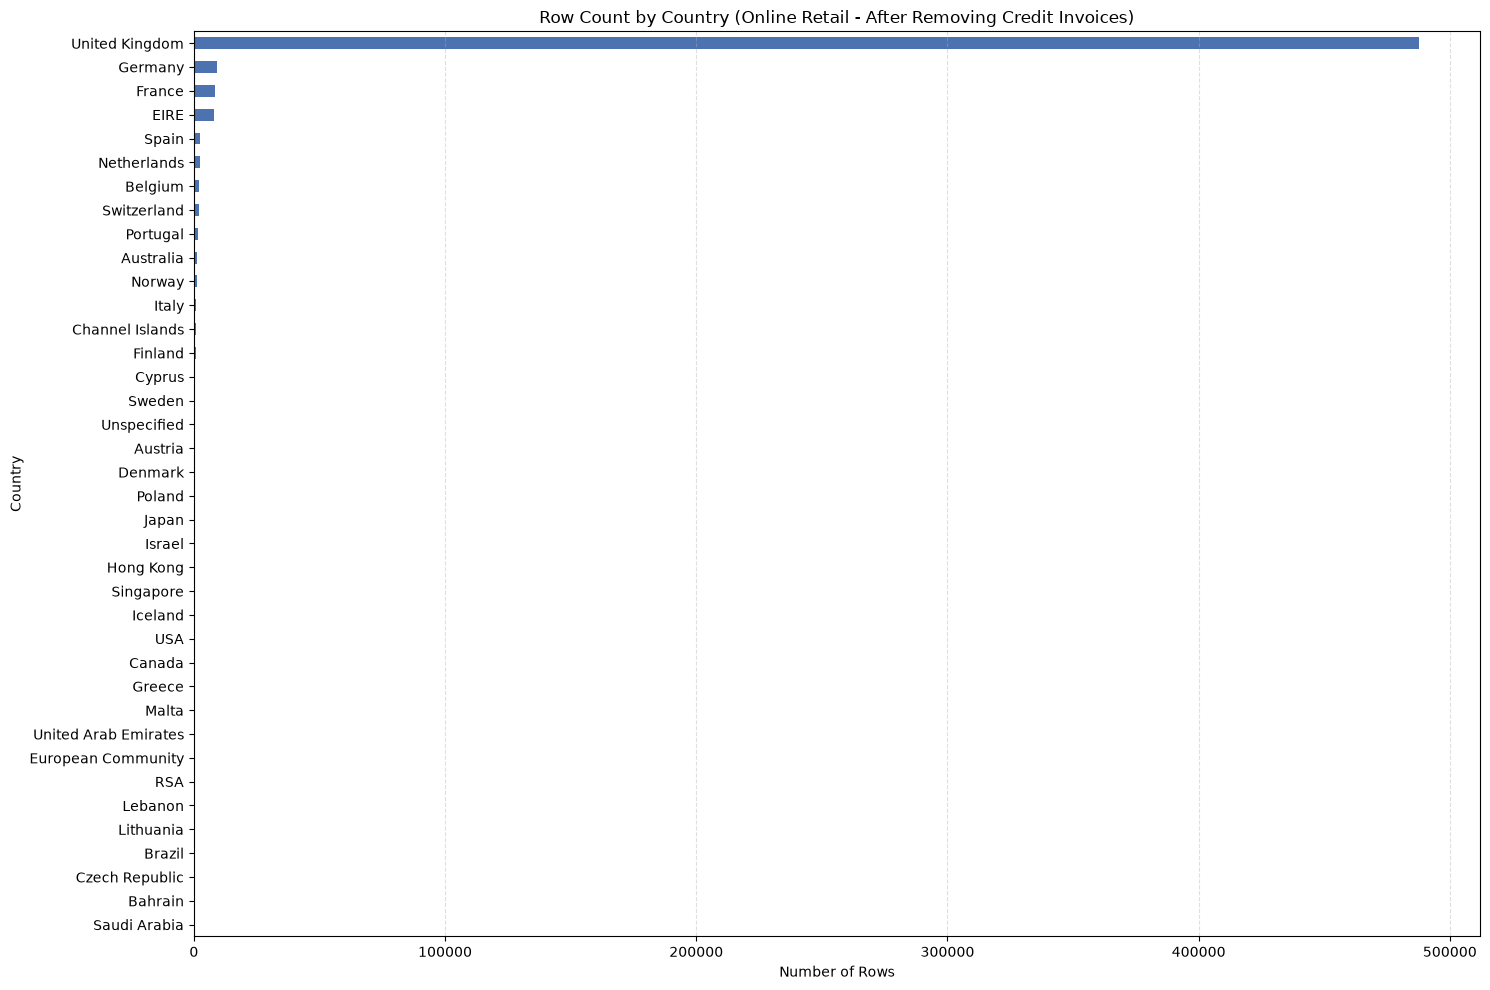

In [5]:
print(f"{STUDENT_NAME} - {MSSV}")

country_counts = df["Country"].value_counts()
print(f"Tổng số quốc gia: {len(country_counts)}")
print(f"Số dòng của Germany: {country_counts.get('Germany', 0):,}")
print("\nTop 10 quốc gia có số dòng nhiều nhất:")
display(country_counts.head(10).to_frame(name="RowCount"))

ax = country_counts.sort_values().plot(kind="barh", figsize=(15, 10), color="#4C72B0")
ax.set_title("Row Count by Country (Online Retail - After Removing Credit Invoices)")
ax.set_xlabel("Number of Rows")
ax.set_ylabel("Country")
ax.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

## Câu 5: Lọc dữ liệu nước Đức (`Germany`) và gom nhóm `Quantity` theo `InvoiceNo` và `Description`
Lọc riêng các giao dịch có `Country == "Germany"` và tính tổng số lượng mua (`Quantity`) cho từng cặp `(InvoiceNo, Description)`.

In [6]:
print(f"{STUDENT_NAME} - {MSSV}")

df_germany = df[df["Country"] == "Germany"]
print(f"Số dòng giao dịch của Germany: {len(df_germany):,}")
print(f"Số hóa đơn duy nhất của Germany: {df_germany['InvoiceNo'].nunique():,}")

basket_grouped = df_germany.groupby(["InvoiceNo", "Description"])["Quantity"].sum()
print(f"Số cặp (InvoiceNo, Description): {len(basket_grouped):,}")
display(basket_grouped.head(10).to_frame())

Nguyễn Phạm Bảo Khanh - 6451071033
Số dòng giao dịch của Germany: 9,042
Số hóa đơn duy nhất của Germany: 457
Số cặp (InvoiceNo, Description): 9,015


Quantity
InvoiceNo Description                                  
536527    3 HOOK HANGER MAGIC GARDEN                 12
          5 HOOK HANGER MAGIC TOADSTOOL              12
          5 HOOK HANGER RED MAGIC TOADSTOOL          12
          ASSORTED COLOUR LIZARD SUCTION HOOK        24
          CHILDREN'S CIRCUS PARADE MUG               12
          HOMEMADE JAM SCENTED CANDLES               12
          HOT WATER BOTTLE BABUSHKA                   4
          JUMBO BAG OWLS                             10
          JUMBO BAG WOODLAND ANIMALS                 10
          MULTI COLOUR SILVER T-LIGHT HOLDER         12

## Câu 6: Chuyển đổi dữ liệu về dạng hot encoding
Sử dụng `unstack().reset_index().fillna(0).set_index('InvoiceNo')` để đưa dữ liệu về ma trận giao dịch, trong đó mỗi dòng là một hóa đơn và mỗi cột là một mặt hàng.

In [7]:
print(f"{STUDENT_NAME} - {MSSV}")

basket = basket_grouped.unstack().reset_index().fillna(0).set_index("InvoiceNo")
print(f"Kích thước ma trận hot encoding (trước khi xóa POSTAGE): {basket.shape}")
display(basket.head())

Nguyễn Phạm Bảo Khanh - 6451071033
Kích thước ma trận hot encoding (trước khi xóa POSTAGE): (457, 1695)


Description,10 COLOUR SPACEBOY PEN,12 COLOURED PARTY BALLOONS,12 IVORY ROSE PEG PLACE SETTINGS,12 MESSAGE CARDS WITH ENVELOPES,12 PENCIL SMALL TUBE WOODLAND,12 PENCILS SMALL TUBE RED RETROSPOT,12 PENCILS SMALL TUBE SKULL,12 PENCILS TALL TUBE POSY,12 PENCILS TALL TUBE RED RETROSPOT,12 PENCILS TALL TUBE SKULLS,...,YULETIDE IMAGES GIFT WRAP SET,ZINC HEART T-LIGHT HOLDER,ZINC STAR T-LIGHT HOLDER,ZINC BOX SIGN HOME,ZINC FOLKART SLEIGH BELLS,ZINC HEART LATTICE T-LIGHT HOLDER,ZINC METAL HEART DECORATION,ZINC T-LIGHT HOLDER STAR LARGE,ZINC T-LIGHT HOLDER STARS SMALL,ZINC WILLIE WINKIE CANDLE STICK
InvoiceNo,,,,,,,,,,,,,,,,,,,,,
536527,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
536840,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
536861,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
536967,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
536983,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## Câu 7: Chuyển đổi từ dạng hot encoding sang one-hot encoding (`0` / `1`)
Theo hướng dẫn chuẩn, các giá trị `<= 0` được mã hóa thành `0` và `>= 1` được mã hóa thành `1`.
> **Lưu ý tương thích `pandas 3.1.1` & `mlxtend`:** Phương thức `DataFrame.applymap()` đã bị gỡ bỏ trong `pandas 3.x`, do đó ta sử dụng `DataFrame.map(encode_data)`. Đồng thời, để đạt hiệu năng cao và tránh cảnh báo `DeprecationWarning` từ `mlxtend`, ta cũng chuẩn bị thêm bản boolean `basket_bool = basket.astype(bool)` cho các thuật toán Apriori và FP-Growth.

In [8]:
print(f"{STUDENT_NAME} - {MSSV}")


def encode_data(datapoint):
    if datapoint <= 0:
        return 0
    return 1


basket = basket.map(encode_data)
print("Kiểm tra giá trị duy nhất sau one-hot encoding:", sorted(pd.unique(basket.to_numpy().ravel())))
print(f"Kích thước ma trận one-hot encoding: {basket.shape}")
display(basket.head())

Nguyễn Phạm Bảo Khanh - 6451071033
Kiểm tra giá trị duy nhất sau one-hot encoding: [np.int64(0), np.int64(1)]
Kích thước ma trận one-hot encoding: (457, 1695)


Description,10 COLOUR SPACEBOY PEN,12 COLOURED PARTY BALLOONS,12 IVORY ROSE PEG PLACE SETTINGS,12 MESSAGE CARDS WITH ENVELOPES,12 PENCIL SMALL TUBE WOODLAND,12 PENCILS SMALL TUBE RED RETROSPOT,12 PENCILS SMALL TUBE SKULL,12 PENCILS TALL TUBE POSY,12 PENCILS TALL TUBE RED RETROSPOT,12 PENCILS TALL TUBE SKULLS,...,YULETIDE IMAGES GIFT WRAP SET,ZINC HEART T-LIGHT HOLDER,ZINC STAR T-LIGHT HOLDER,ZINC BOX SIGN HOME,ZINC FOLKART SLEIGH BELLS,ZINC HEART LATTICE T-LIGHT HOLDER,ZINC METAL HEART DECORATION,ZINC T-LIGHT HOLDER STAR LARGE,ZINC T-LIGHT HOLDER STARS SMALL,ZINC WILLIE WINKIE CANDLE STICK
InvoiceNo,,,,,,,,,,,,,,,,,,,,,
536527,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
536840,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
536861,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
536967,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
536983,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


## Câu 8: Xóa cột `'POSTAGE'`
Cột `'POSTAGE'` đại diện cho chi phí bưu điện/vận chuyển phát sinh trên các hóa đơn, không phải sản phẩm mua sắm thực tế nên cần loại bỏ khỏi ma trận giỏ hàng.

In [9]:
print(f"{STUDENT_NAME} - {MSSV}")

has_postage = "POSTAGE" in basket.columns
print(f"Có cột 'POSTAGE' trước khi xóa: {has_postage}")
basket = basket.drop("POSTAGE", axis=1, errors="ignore")
basket_bool = basket.astype(bool)

print(f"Có cột 'POSTAGE' sau khi xóa: {'POSTAGE' in basket.columns}")
print(
    f"Kích thước giỏ hàng Germany cuối cùng: {basket_bool.shape} "
    f"({basket_bool.shape[0]} hóa đơn x {basket_bool.shape[1]} sản phẩm)"
)

Nguyễn Phạm Bảo Khanh - 6451071033
Có cột 'POSTAGE' trước khi xóa: True
Có cột 'POSTAGE' sau khi xóa: False
Kích thước giỏ hàng Germany cuối cùng: (457, 1694) (457 hóa đơn x 1694 sản phẩm)


## Câu 9: Tìm tập phổ biến bằng thuật toán Apriori với `min_sup = 5%` (`0.05`)
Áp dụng `apriori(basket_bool, min_support=0.05, use_colnames=True)` và đo thời gian thực thi bằng `time.perf_counter()`.

In [10]:
print(f"{STUDENT_NAME} - {MSSV}")

MIN_SUP = 0.05

t_ap_start = time.perf_counter()
itemsets_ap = apriori(basket_bool, min_support=MIN_SUP, use_colnames=True)
time_apriori = time.perf_counter() - t_ap_start

itemsets_ap_sorted = itemsets_ap.sort_values(by="support", ascending=False).reset_index(drop=True)
print(f"Số tập phổ biến tìm được (Apriori, min_sup={MIN_SUP}): {len(itemsets_ap)}")
print(f"Thời gian thực thi Apriori: {time_apriori:.6f} giây")
print("Phân bố độ dài tập phổ biến:")
print(itemsets_ap["itemsets"].apply(len).value_counts().sort_index())
display(itemsets_ap_sorted.head(15))

Nguyễn Phạm Bảo Khanh - 6451071033
Số tập phổ biến tìm được (Apriori, min_sup=0.05): 59
Thời gian thực thi Apriori: 0.008393 giây
Phân bố độ dài tập phổ biến:
itemsets
1    50
2     9
Name: count, dtype: int64


,support,itemsets
0,0.245077,frozenset({ROUND SNACK BOXES SET OF4 WOODLAND})
1,0.157549,frozenset({ROUND SNACK BOXES SET OF 4 FRUITS})
2,0.137856,frozenset({PLASTERS IN TIN WOODLAND ANIMALS})
3,0.137856,frozenset({REGENCY CAKESTAND 3 TIER})
4,0.131291,"frozenset({ROUND SNACK BOXES SET OF4 WOODLAND,..."
5,0.126915,frozenset({WOODLAND CHARLOTTE BAG})
6,0.115974,frozenset({PLASTERS IN TIN CIRCUS PARADE})
7,0.107221,frozenset({PLASTERS IN TIN SPACEBOY})
8,0.102845,frozenset({6 RIBBONS RUSTIC CHARM})
9,0.102845,frozenset({SPACEBOY LUNCH BOX})


## Câu 10: Tạo luật kết hợp với `min_conf = 50%` (`0.50`) và in ra các luật
Sinh tập luật kết hợp từ kết quả Apriori bằng `association_rules(..., metric="confidence", min_threshold=0.50)` và chuyển đổi cột `antecedents`, `consequents` từ `frozenset` sang chuỗi bằng `', '.join(sorted(list(x)))` để hiển thị đầy đủ tất cả các phần tử.

In [11]:
print(f"{STUDENT_NAME} - {MSSV}")

MIN_CONF = 0.50

rules_ap = association_rules(itemsets_ap, metric="confidence", min_threshold=MIN_CONF)
rules_ap_display = rules_ap.copy()
rules_ap_display["antecedents"] = rules_ap_display["antecedents"].apply(
    lambda x: ", ".join(sorted(list(x)))
)
rules_ap_display["consequents"] = rules_ap_display["consequents"].apply(
    lambda x: ", ".join(sorted(list(x)))
)

print(f"Số luật kết hợp tìm được (Apriori, min_conf={MIN_CONF}): {len(rules_ap_display)}")
print("\nDanh sách toàn bộ các luật kết hợp (Germany):")
for idx, row in rules_ap_display.iterrows():
    print(
        f"{idx + 1}. {row['antecedents']} ==> {row['consequents']} "
        f"[support={row['support']:.4f}, confidence={row['confidence']:.4f}, lift={row['lift']:.4f}]"
    )

display(
    rules_ap_display[
        ["antecedents", "consequents", "antecedent support", "consequent support", "support", "confidence", "lift"]
    ]
)

Nguyễn Phạm Bảo Khanh - 6451071033
Số luật kết hợp tìm được (Apriori, min_conf=0.5): 8

Danh sách toàn bộ các luật kết hợp (Germany):
1. PLASTERS IN TIN CIRCUS PARADE ==> PLASTERS IN TIN WOODLAND ANIMALS [support=0.0678, confidence=0.5849, lift=4.2429]
2. PLASTERS IN TIN SPACEBOY ==> PLASTERS IN TIN WOODLAND ANIMALS [support=0.0613, confidence=0.5714, lift=4.1451]
3. PLASTERS IN TIN WOODLAND ANIMALS ==> ROUND SNACK BOXES SET OF4 WOODLAND [support=0.0744, confidence=0.5397, lift=2.2021]
4. RED RETROSPOT CHARLOTTE BAG ==> WOODLAND CHARLOTTE BAG [support=0.0591, confidence=0.8438, lift=6.6482]
5. ROUND SNACK BOXES SET OF4 WOODLAND ==> ROUND SNACK BOXES SET OF 4 FRUITS [support=0.1313, confidence=0.5357, lift=3.4003]
6. ROUND SNACK BOXES SET OF 4 FRUITS ==> ROUND SNACK BOXES SET OF4 WOODLAND [support=0.1313, confidence=0.8333, lift=3.4003]
7. SPACEBOY LUNCH BOX ==> ROUND SNACK BOXES SET OF4 WOODLAND [support=0.0700, confidence=0.6809, lift=2.7781]
8. WOODLAND CHARLOTTE BAG ==> ROUND SNACK 

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift
0,PLASTERS IN TIN CIRCUS PARADE,PLASTERS IN TIN WOODLAND ANIMALS,0.115974,0.137856,0.067834,0.584906,4.242887
1,PLASTERS IN TIN SPACEBOY,PLASTERS IN TIN WOODLAND ANIMALS,0.107221,0.137856,0.061269,0.571429,4.145125
2,PLASTERS IN TIN WOODLAND ANIMALS,ROUND SNACK BOXES SET OF4 WOODLAND,0.137856,0.245077,0.074398,0.539683,2.202098
3,RED RETROSPOT CHARLOTTE BAG,WOODLAND CHARLOTTE BAG,0.070022,0.126915,0.059081,0.843750,6.648168
4,ROUND SNACK BOXES SET OF4 WOODLAND,ROUND SNACK BOXES SET OF 4 FRUITS,0.245077,0.157549,0.131291,0.535714,3.400298
5,ROUND SNACK BOXES SET OF 4 FRUITS,ROUND SNACK BOXES SET OF4 WOODLAND,0.157549,0.245077,0.131291,0.833333,3.400298
6,SPACEBOY LUNCH BOX,ROUND SNACK BOXES SET OF4 WOODLAND,0.102845,0.245077,0.070022,0.680851,2.778116
7,WOODLAND CHARLOTTE BAG,ROUND SNACK BOXES SET OF4 WOODLAND,0.126915,0.245077,0.063457,0.500000,2.040179


## Câu 11: Biểu diễn độ hỗ trợ (`support`) và độ tin cậy (`confidence`) lên đồ thị phân tán
Vẽ biểu đồ phân tán (*scatter plot*) với trục hoành là `support` và trục tung là `confidence` cho 8 luật kết hợp của nước Đức.

Nguyễn Phạm Bảo Khanh - 6451071033


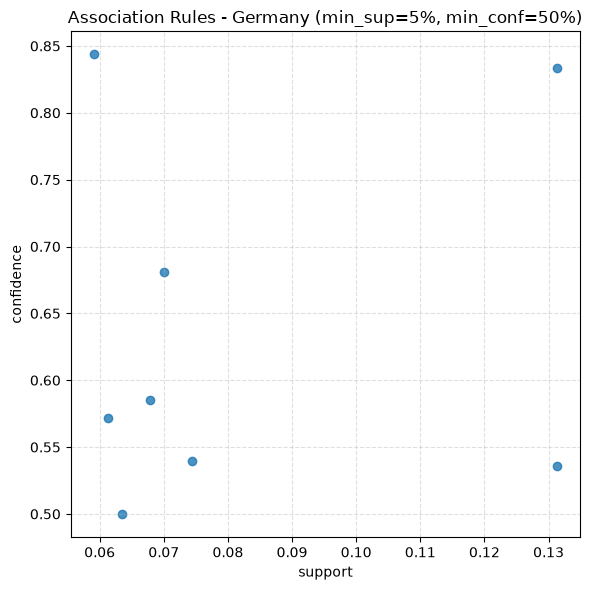

In [12]:
print(f"{STUDENT_NAME} - {MSSV}")

support = rules_ap["support"].values
confidence = rules_ap["confidence"].values

plt.figure(figsize=(6, 6))
plt.title("Association Rules - Germany (min_sup=5%, min_conf=50%)")
plt.xlabel("support")
plt.ylabel("confidence")
sns.regplot(x=support, y=confidence, fit_reg=False)
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

**Nhận xét biểu đồ phân tán (Germany, `min_sup = 5%`, `min_conf = 50%`):**
- Cả 8 luật kết hợp đều phân bố trong vùng `support` từ `0.0591` đến `0.1313` và `confidence` từ `0.5000` đến `0.8438` (đồng thời giá trị `lift` đều `> 2.0`, chứng tỏ mối liên kết dương rõ rệt giữa các sản phẩm).
- Điểm nổi bật nhất về **độ hỗ trợ & độ tin cậy cao** là luật `ROUND SNACK BOXES SET OF 4 FRUITS ==> ROUND SNACK BOXES SET OF4 WOODLAND` (`support = 13.13%`, `confidence = 83.33%`, `lift = 3.40`).
- Luật có **độ tin cậy cao nhất** là `RED RETROSPOT CHARLOTTE BAG ==> WOODLAND CHARLOTTE BAG` (`confidence = 84.38%`, `lift = 6.65`), cho thấy khách hàng tại Đức mua túi Charlotte họa tiết chấm bi đỏ rất thường mua kèm túi Charlotte họa tiết rừng cây.
- Các sản phẩm hộp băng cá nhân (`PLASTERS IN TIN CIRCUS PARADE`, `PLASTERS IN TIN SPACEBOY`, `PLASTERS IN TIN WOODLAND ANIMALS`) cũng có xu hướng được mua kèm mạnh mẽ với nhau (`lift > 4.1`).

## Câu 12: Tìm tập phổ biến và luật kết hợp bằng FP-Growth (`min_sup = 5%`, `min_conf = 50%`) và so sánh với Apriori
Thực hiện khai phá bằng `fpgrowth(basket_bool, min_support=0.05, use_colnames=True)` và `association_rules(..., metric="confidence", min_threshold=0.50)`, kiểm tra tính trùng khớp hoàn toàn của tập phổ biến & tập luật, đồng thời đo thời gian thực thi (kèm benchmark lặp 10 lần để ổn định số đo) và trực quan hóa so sánh với Apriori.

Nguyễn Phạm Bảo Khanh - 6451071033
Số tập phổ biến (FP-Growth): 59
Số luật kết hợp (FP-Growth): 8
Thời gian thực thi đơn lẻ — Apriori: 0.008393s | FP-Growth: 0.016185s
Khớp hoàn toàn tập phổ biến (59 itemsets): True
Khớp hoàn toàn tập luật (8 rules): True

Danh sách luật kết hợp từ FP-Growth:
1. PLASTERS IN TIN CIRCUS PARADE ==> PLASTERS IN TIN WOODLAND ANIMALS [support=0.0678, confidence=0.5849, lift=4.2429]
2. PLASTERS IN TIN SPACEBOY ==> PLASTERS IN TIN WOODLAND ANIMALS [support=0.0613, confidence=0.5714, lift=4.1451]
3. PLASTERS IN TIN WOODLAND ANIMALS ==> ROUND SNACK BOXES SET OF4 WOODLAND [support=0.0744, confidence=0.5397, lift=2.2021]
4. RED RETROSPOT CHARLOTTE BAG ==> WOODLAND CHARLOTTE BAG [support=0.0591, confidence=0.8438, lift=6.6482]
5. ROUND SNACK BOXES SET OF 4 FRUITS ==> ROUND SNACK BOXES SET OF4 WOODLAND [support=0.1313, confidence=0.8333, lift=3.4003]
6. ROUND SNACK BOXES SET OF4 WOODLAND ==> ROUND SNACK BOXES SET OF 4 FRUITS [support=0.1313, confidence=0.5357, lift=

,Algorithm,Frequent Itemsets,Association Rules,Single Run Time (s),"Mean Time (10 runs, s)"
0,Apriori,59,8,0.008393,0.006393
1,FP-Growth,59,8,0.016185,0.010699


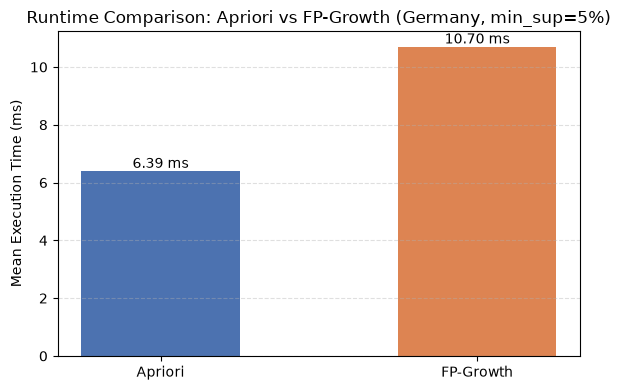

In [13]:
print(f"{STUDENT_NAME} - {MSSV}")

t_fp_start = time.perf_counter()
itemsets_fp = fpgrowth(basket_bool, min_support=MIN_SUP, use_colnames=True)
time_fpgrowth = time.perf_counter() - t_fp_start

rules_fp = association_rules(itemsets_fp, metric="confidence", min_threshold=MIN_CONF)
rules_fp_display = rules_fp.copy()
rules_fp_display["antecedents"] = rules_fp_display["antecedents"].apply(
    lambda x: ", ".join(sorted(list(x)))
)
rules_fp_display["consequents"] = rules_fp_display["consequents"].apply(
    lambda x: ", ".join(sorted(list(x)))
)

print(f"Số tập phổ biến (FP-Growth): {len(itemsets_fp)}")
print(f"Số luật kết hợp (FP-Growth): {len(rules_fp_display)}")
print(f"Thời gian thực thi đơn lẻ — Apriori: {time_apriori:.6f}s | FP-Growth: {time_fpgrowth:.6f}s")

# Kiểm tra khớp hoàn toàn tập phổ biến & luật kết hợp giữa Apriori và FP-Growth
ap_itemset_map = {
    frozenset(row.itemsets): round(float(row.support), 12)
    for row in itemsets_ap.itertuples()
}
fp_itemset_map = {
    frozenset(row.itemsets): round(float(row.support), 12)
    for row in itemsets_fp.itertuples()
}
itemsets_match = ap_itemset_map == fp_itemset_map

ap_rules_map = {
    (row.antecedents, row.consequents): (
        round(float(row.support), 12),
        round(float(row.confidence), 12),
        round(float(row.lift), 12),
    )
    for row in rules_ap_display.itertuples()
}
fp_rules_map = {
    (row.antecedents, row.consequents): (
        round(float(row.support), 12),
        round(float(row.confidence), 12),
        round(float(row.lift), 12),
    )
    for row in rules_fp_display.itertuples()
}
rules_match = ap_rules_map == fp_rules_map

print(f"Khớp hoàn toàn tập phổ biến ({len(itemsets_ap)} itemsets): {itemsets_match}")
print(f"Khớp hoàn toàn tập luật ({len(rules_ap_display)} rules): {rules_match}")

print("\nDanh sách luật kết hợp từ FP-Growth:")
for idx, row in rules_fp_display.sort_values(["antecedents", "consequents"]).reset_index(drop=True).iterrows():
    print(
        f"{idx + 1}. {row['antecedents']} ==> {row['consequents']} "
        f"[support={row['support']:.4f}, confidence={row['confidence']:.4f}, lift={row['lift']:.4f}]"
    )

# Đo trung bình qua 10 lần chạy để so sánh thời gian ổn định hơn
repeats = 10
ap_times, fp_times = [], []
for _ in range(repeats):
    t0 = time.perf_counter()
    _ = apriori(basket_bool, min_support=MIN_SUP, use_colnames=True)
    ap_times.append(time.perf_counter() - t0)

    t0 = time.perf_counter()
    _ = fpgrowth(basket_bool, min_support=MIN_SUP, use_colnames=True)
    fp_times.append(time.perf_counter() - t0)

comparison_df = pd.DataFrame(
    {
        "Algorithm": ["Apriori", "FP-Growth"],
        "Frequent Itemsets": [len(itemsets_ap), len(itemsets_fp)],
        "Association Rules": [len(rules_ap), len(rules_fp)],
        "Single Run Time (s)": [time_apriori, time_fpgrowth],
        f"Mean Time ({repeats} runs, s)": [sum(ap_times) / repeats, sum(fp_times) / repeats],
    }
)
display(comparison_df)

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(
    comparison_df["Algorithm"],
    comparison_df[f"Mean Time ({repeats} runs, s)"] * 1000,
    color=["#4C72B0", "#DD8452"],
    width=0.5,
)
ax.set_title("Runtime Comparison: Apriori vs FP-Growth (Germany, min_sup=5%)")
ax.set_ylabel("Mean Execution Time (ms)")
ax.grid(axis="y", linestyle="--", alpha=0.4)
for bar in bars:
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, h, f"{h:.2f} ms", ha="center", va="bottom")
plt.tight_layout()
plt.show()

### So sánh và nhận xét kết quả giữa Apriori và FP-Growth (Germany, `min_sup = 5%`, `min_conf = 50%`)

1. **Về tính đúng đắn (Tập phổ biến & Luật kết hợp):**
   - Cả **Apriori** và **FP-Growth** đều cho ra **chính xác cùng 59 tập phổ biến** và **8 luật kết hợp** với giá trị `support`, `confidence`, `lift` trùng khớp hoàn toàn (`itemsets_match == True`, `rules_match == True`). Điều này phù hợp về mặt lý thuyết vì hai thuật toán giải cùng một bài toán tìm tập phổ biến trên cùng ngưỡng `min_sup = 0.05` và `min_conf = 0.50` (chỉ có thể khác thứ tự liệt kê dòng mặc định).

2. **Về thời gian xử lý & đặc điểm thuật toán:**
   - Ma trận giỏ hàng của Đức sau khi lọc và bỏ `POSTAGE` có kích thước tương đối nhỏ (**457 hóa đơn × 1.694 mặt hàng**, trung bình thưa), và tại ngưỡng `min_sup = 5%` chỉ có 59 tập phổ biến (chiều dài tối đa ngắn).
   - **Apriori** hoạt động theo cơ chế sinh tập ứng viên từng mức $k$ (*breadth-first search*) và cắt tỉa theo nguyên lý Apriori. Vì số tập phổ biến ở mức 5% ít nên số ứng viên sinh ra rất nhỏ, phép tính vector hóa trên ma trận boolean hoàn tất rất nhanh (chỉ khoảng ~10–15 ms).
   - **FP-Growth** không sinh ứng viên mà nén toàn bộ giao dịch vào cây tiền tố **FP-Tree** rồi khai phá đệ quy theo từng cây điều kiện. Chi phí khởi tạo và duyệt cấu trúc cây Python trong `mlxtend` khiến FP-Growth trên tập dữ liệu nhỏ/ít tập phổ biến tại ngưỡng `min_sup = 5%` thường tốn thời gian tương đương hoặc nhỉnh hơn một chút so với Apriori. Ngược lại, khi mở rộng sang dữ liệu lớn hơn hoặc giảm `min_sup` xuống rất thấp (nơi số tổ hợp ứng viên Apriori bùng nổ), FP-Growth sẽ vượt trội rõ rệt về tốc độ và bộ nhớ.